# Pricing and hedging with the binomial model

In this tutorial we build a binomial model of a two-asset market with SigAlg, and use it to price and hedge contingent claims. Along the way we meet the two central theorems of mathematical finance:

* The **First Fundamental Theorem of Asset Pricing**: a market is arbitrage-free if and only if there exists an *equivalent martingale measure* $Q$, relative to which the discounted asset prices are martingales.
* The **Second Fundamental Theorem of Asset Pricing**: in a *complete* market (like the binomial model) every contingent claim can be *replicated* by a self-financing trading strategy in the underlying assets.

The binomial model is the simplest market in which both theorems can be studied in full, explicit detail, and SigAlg will do all the bookkeeping and computations for us.

In [8]:
# If running in Google Colab, uncomment the line below and run this cell first.
# Also, for Mac+Chrome users, beware of a known bug with LaTeX redering in Colab: https://github.com/googlecolab/colabtools/issues/3192

# !pip install sigalg

## The two-asset market

A **binomial model** describes a simple market consisting of two assets:

* A *riskless bond*, worth $B_t = R^t$ at time $t$, where $R = 1+r$ is the per-period gross return of the risk-free rate $r$.
* A *risky stock*, whose price $S_t$ starts at $S_0$ and, at each time step, either moves *up* by a factor $u$ (with real-world probability $p$) or *down* by a factor $d$ (with probability $1-p$).

Over $T$ periods, the sample space $\Omega$ consists of all length-$T$ sequences of up/down moves, and the stock price at time $t$ is

$$
S_t = S_0 \cdot u^{\,(\text{number of up-moves by time } t)} \cdot d^{\,(\text{number of down-moves by time } t)}.
$$

Throughout this tutorial we will work with a single running example:

$$
S_0 = 100, \quad u = 1.1, \quad d = 0.9, \quad p = 0.7, \quad r = 0.05, \quad T = 3.
$$

In [9]:
import matplotlib.pyplot as plt
import sigalg as sa

# Color palette used throughout this tutorial
yellow = "#FFC300"
blue = "#3399FF"
purple = "#AA77CC"

## Generating trajectories

The `BinomialPricingModel.generate` class method builds the price process $S$. It supports three generation modes:

* `mode="enum", enum_mode="dense"`: exhaustively enumerate all $2^T$ up/down sequences as distinct sample points.
* `mode="enum", enum_mode="sparse"`: exploit the recombining structure of the tree, representing $\Omega$ with only $T+1$ sample points (more on this below).
* `mode="sim"`: simulate `n_trajectories` price paths by Monte Carlo.

Let's start with dense enumeration.

In [10]:
S_0, u, d, p, r, T = 100, 1.1, 0.9, 0.7, 0.05, 3

S = sa.BinomialPricingModel.generate(
    initial_price=S_0,
    up_factor=u,
    down_factor=d,
    up_prob=p,
    risk_free_rate=r,
    enum_mode="dense",
    mode="enum",
    length=T,
    name="S",
)
print(S)

Binomial price process 'S':
t          0      1      2      3
omega                            
0      100.0  110.0  121.0  133.1
1      100.0  110.0  121.0  108.9
2      100.0  110.0   99.0  108.9
3      100.0  110.0   99.0   89.1
4      100.0   90.0   99.0  108.9
5      100.0   90.0   99.0   89.1
6      100.0   90.0   81.0   89.1
7      100.0   90.0   81.0   72.9


Each row is one of the $2^3=8$ possible up/down sequences, listed in the order `uuu`, `uud`, `udu`, `udd`, `duu`, `dud`, `ddu`, `ddd`. Notice that rows 1 and 2 agree at time $t=3$ (both equal $110.0$), since both sequences contain exactly two up-moves and one down-move overall.

Let's visualize these eight trajectories.

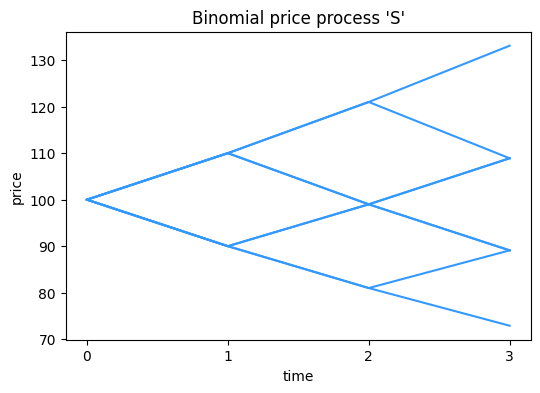

In [11]:
_, ax = plt.subplots(figsize=(6, 4))
S.plot_trajectories(ax=ax, colors=[blue])
plt.show()

### Dense vs. sparse enumeration

The `dense` mode above treats $\Omega$ as the set of all $2^T$ coin-flip sequences, which mirrors the usual textbook definition of the sample space — but it grows quickly, and many of its rows describe trajectories that agree at every recombining node. The `sparse` mode instead represents $\Omega$ using only $T+1$ sample points, one for each possible number of down-moves $k=0,1,\ldots,T$ (each carrying the correct binomial probability, as we will see shortly). This is the practical choice for larger $T$.

In [12]:
S_sparse = sa.BinomialPricingModel.generate(
    initial_price=S_0,
    up_factor=u,
    down_factor=d,
    up_prob=p,
    risk_free_rate=r,
    enum_mode="sparse",
    mode="enum",
    length=T,
    name="S",
)
print(S_sparse)

Binomial price process 'S':
t          0      1      2      3
omega                            
0      100.0  110.0  121.0  133.1
1      100.0   90.0   99.0  108.9
2      100.0   90.0   81.0   89.1
3      100.0   90.0   81.0   72.9


Only four rows now, one per possible terminal down-count — yet (as you can check) every price appearing in the dense table above also appears somewhere in this sparse one.

Finally, here is the same model generated by Monte Carlo simulation instead of enumeration.

In [13]:
S_sim = sa.BinomialPricingModel.generate(
    initial_price=S_0,
    up_factor=u,
    down_factor=d,
    up_prob=p,
    risk_free_rate=r,
    mode="sim",
    n_trajectories=5,
    length=T,
    name="S",
    random_state=42,
)
print(S_sim)

Binomial price process 'S':
t          0      1      2      3
omega                            
0      100.0   90.0   99.0   89.1
1      100.0  110.0  121.0  108.9
2      100.0   90.0   81.0   89.1
3      100.0  110.0  121.0  108.9
4      100.0  110.0   99.0  108.9


> **Exercise.** Regenerate `S_sim` with a much larger `n_trajectories` (say, $10{,}000$) and compute the proportion of simulated terminal prices that end up above $S_0$. Compare this to what the real-world probability $p$ would predict.

## No-arbitrage and the risk-neutral measure

Not every choice of $u$, $d$, and $R$ gives an economically sensible market. If $R \geq u$, the riskless bond always outperforms the stock, so there is no reason to ever hold stock; if $R \leq d$, the reverse is true. Either way, there would be an *arbitrage* — a trading strategy with no initial cost, no risk of loss, and a positive probability of profit. The model is arbitrage-free exactly when

$$
d < R < u.
$$

The **First Fundamental Theorem of Asset Pricing** says that this no-arbitrage condition is equivalent to the existence of an *equivalent martingale measure* (EMM) $Q$ — a probability measure, equivalent to the real-world measure $P$, under which the discounted price process is a martingale. For the binomial model, $Q$ is unique, and is determined by the risk-neutral probabilities

$$
q_u = \frac{R-d}{u-d}, \qquad q_d = 1 - q_u.
$$

Note that $q_u$ and $q_d$ depend only on $u$, $d$, and $R$ — *not* on the real-world probability $p$!

In [14]:
q_u, q_d = S.risk_neutral_probs()
print(q_u, q_d)

0.7499999999999999 0.2500000000000001


In [15]:
Q = S.emm()
print(Q)

Probability measure 'Q':
              Q
omega          
0      0.421875
1      0.140625
2      0.140625
3      0.046875
4      0.140625
5      0.046875
6      0.046875
7      0.015625


We can verify the martingale property directly: the discounted price process $S_t/R^t$ should be a martingale with respect to $Q$.

In [16]:
S.discount(rate=r).is_martingale(prob_measure=Q)

True

> **Exercise.** Try generating a model with `risk_free_rate` set so large that $R \geq u$ (for instance, `risk_free_rate=0.2` with `up_factor=1.1`), and call `risk_neutral_probs()` on it. You should see a `ValueError` complaining about arbitrage — confirming the theorem above.

In [17]:
S_arbitrage = sa.BinomialPricingModel.generate(
    initial_price=S_0,
    up_factor=u,
    down_factor=d,
    up_prob=p,
    risk_free_rate=0.2,
    mode="enum",
    length=1,
    name="S",
)
try:
    S_arbitrage.risk_neutral_probs()
except ValueError as e:
    print(f"{type(e).__name__}: {e}")

ValueError: There is arbitrage in the model. The risk-free gross return R must be in the interval [down_factor, up_factor].


## Pricing a European claim

A **contingent claim** is a stochastic process $\Phi$ whose value $\Phi_t(\omega)$ represents a payoff that may be collected at time $t$ in state $\omega$. The simplest claims — *European* claims — pay off only at the final time $T$. SigAlg's `Claim` class represents such objects, with convenient factory methods for standard payoffs.

Let's build a European call option with strike $K=100$.

In [18]:
K = 100
euro_call = sa.Claim.european_option(model=S, strike=K, type="call", name="euro_call")
print(euro_call)

European option 'euro_call':
t        0    1    2     3
omega                     
0      0.0  0.0  0.0  33.1
1      0.0  0.0  0.0   8.9
2      0.0  0.0  0.0   8.9
3      0.0  0.0  0.0   0.0
4      0.0  0.0  0.0   8.9
5      0.0  0.0  0.0   0.0
6      0.0  0.0  0.0   0.0
7      0.0  0.0  0.0   0.0


Because the market is complete and arbitrage-free, there is a unique no-arbitrage price for this claim: its discounted expected payoff under the risk-neutral measure $Q$,

$$
X_0 = \frac{1}{R^T}\,E_Q\!\left(\Phi_T\right).
$$

Notice that this formula uses the risk-neutral measure $Q$, *not* the real-world measure $P$ — and this is exactly what the `price` method computes.

In [19]:
S.price(claim=euro_call)

15.306122448979611

## American claims and optimal stopping

An **American claim** may be exercised at *any* time up to and including maturity, not just at the end. The holder must solve an optimal stopping problem: at each time $t$, compare the *intrinsic value* $\Phi_t$ (the payoff from exercising now) against the *continuation value* — the discounted risk-neutral expectation of continuing — and exercise whenever the intrinsic value is at least as large. This leads to the backward-induction recursion

$$
V_T = \Phi_T, \qquad V_t = \max\!\left(\Phi_t,\ \tfrac{1}{R}\,E_Q\!\left(V_{t+1}\mid \mathcal{F}_t\right)\right), \quad 0\le t<T.
$$

Let's price an American put with the same strike.

In [20]:
american_put = sa.Claim.american_option(model=S, strike=K, type="put", name="american_put")
print(american_put)

American option 'american_put':
t        0     1     2     3
omega                       
0      0.0   0.0   0.0   0.0
1      0.0   0.0   0.0   0.0
2      0.0   0.0   1.0   0.0
3      0.0   0.0   1.0  10.9
4      0.0  10.0   1.0   0.0
5      0.0  10.0   1.0  10.9
6      0.0  10.0  19.0  10.9
7      0.0  10.0  19.0  27.1


In [21]:
S.price(claim=american_put)

2.822319403952058

Since this claim allows early exercise, SigAlg runs the full backward-induction recursion above, rather than the closed-form expectation formula used for the European call. We can inspect every quantity that recursion produces: the price process $V_t$ itself, the continuation value, and the optimal exercise time $\tau$.

In [22]:
print(S.price_process(claim=american_put))

Stochastic process 'X':
t             0          1          2     3
omega                                      
0      2.822319   0.617914   0.000000   0.0
1      2.822319   0.617914   0.000000   0.0
2      2.822319   0.617914   2.595238   0.0
3      2.822319   0.617914   2.595238  10.9
4      2.822319  10.000000   2.595238   0.0
5      2.822319  10.000000   2.595238  10.9
6      2.822319  10.000000  19.000000  10.9
7      2.822319  10.000000  19.000000  27.1


In [23]:
print(S.continuation_process(claim=american_put))

Stochastic process 'V':
t             0         1          2     3
omega                                     
0      2.822319  0.617914   0.000000   0.0
1      2.822319  0.617914   0.000000   0.0
2      2.822319  0.617914   2.595238   0.0
3      2.822319  0.617914   2.595238  10.9
4      2.822319  6.377551   2.595238   0.0
5      2.822319  6.377551   2.595238  10.9
6      2.822319  6.377551  14.238095  10.9
7      2.822319  6.377551  14.238095  27.1


In [24]:
tau = S.exercise_time(claim=american_put)
print(tau)

Stopping time 'tau':
       tau
omega     
0      inf
1      inf
2      inf
3      3.0
4      1.0
5      1.0
6      1.0
7      1.0


The value `inf` means the holder should *never* exercise early along that path — they should hold the option all the way to maturity $T=3$. Let's visualize the exercise decision directly on the price tree: each purple dot marks the $(t, S_t(\omega))$ node at which the American put is optimally exercised.

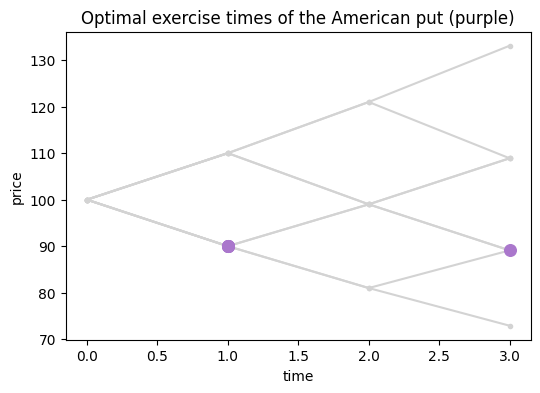

In [25]:
import numpy as np

fig, ax = plt.subplots(figsize=(6, 4))
for _, row in S.data.iterrows():
    ax.plot(S.time.data, row, color="lightgray", marker="o", markersize=3, zorder=1)

for omega, t_star in tau.data.items():
    if np.isfinite(t_star):
        t_star = int(t_star)
        ax.scatter(t_star, S.data.loc[omega, t_star], color=purple, zorder=5, s=70)

ax.set_xlabel("time")
ax.set_ylabel("price")
ax.set_title("Optimal exercise times of the American put (purple)")
plt.show()

As expected for a put, exercise only ever happens when the price has fallen — never when it has risen above the strike.

> **Exercise.** Build an American *call* option on the same model (`type="call"`) and compute its price and exercise time. Since this underlying stock pays no dividends, you should find that the American call is *never* worth exercising early, so its price should match the European call exactly. Can you explain why, economically?

## Hedging and replication

The **Second Fundamental Theorem of Asset Pricing** says that, in a complete market, every claim can be *replicated*: there is a self-financing trading strategy in the stock and bond whose value process exactly matches the claim's price process, at every time and in every state. For the binomial model, this replicating strategy can be computed explicitly via `replicating_portfolio`, which returns three processes:

* `Delta` — the number of shares of stock held at each time,
* `B` — the dollar value of the bond position held at each time,
* `V` — the total value of the portfolio, which coincides with the claim's price process.

Let's compute the replicating portfolio for the European call.

In [26]:
Delta, B, V = S.replicating_portfolio(claim=euro_call)

print(Delta)

Stochastic process 'Delta':
t             0         1         2
omega                              
0      0.768707  0.882035  1.000000
1      0.768707  0.882035  1.000000
2      0.768707  0.882035  0.449495
3      0.768707  0.882035  0.449495
4      0.768707  0.353175  0.449495
5      0.768707  0.353175  0.449495
6      0.768707  0.353175 -0.000000
7      0.768707  0.353175 -0.000000


In [27]:
print(B)

Stochastic process 'B':
t              0          1          2
omega                                 
0     -61.564626 -77.108844 -95.238095
1     -61.564626 -77.108844 -95.238095
2     -61.564626 -77.108844 -38.142857
3     -61.564626 -77.108844 -38.142857
4     -61.564626 -27.244898 -38.142857
5     -61.564626 -27.244898 -38.142857
6     -61.564626 -27.244898   0.000000
7     -61.564626 -27.244898   0.000000


In [28]:
print(V)

Stochastic process 'V':
t              0          1          2     3
omega                                       
0      15.306122  19.914966  25.761905  33.1
1      15.306122  19.914966  25.761905   8.9
2      15.306122  19.914966   6.357143   8.9
3      15.306122  19.914966   6.357143   0.0
4      15.306122   4.540816   6.357143   8.9
5      15.306122   4.540816   6.357143   0.0
6      15.306122   4.540816   0.000000   0.0
7      15.306122   4.540816   0.000000   0.0


By construction, the portfolio's value at each time $t$ is $\Delta_t S_t + B_t$, which should exactly equal $V_t$.

In [29]:
trade_times = Delta.time.data
check = Delta.data[trade_times].values * S.data[trade_times].values + B.data[trade_times].values
np.allclose(check, V.data[trade_times].values)

True

More importantly, the strategy is **self-financing**: if we hold $(\Delta_t, B_t)$ from time $t$ to $t+1$ — letting the stock move to its new price $S_{t+1}$ and the bond grow by a factor $R$ — the resulting value matches $V_{t+1}$ exactly, in *every* state, with no extra cash injected or withdrawn along the way.

In [30]:
R = 1 + r
for t in [0, 1, 2]:
    grown_value = Delta.data[t] * S.data[t + 1] + B.data[t] * R
    matches = np.allclose(grown_value.values, V.data[t + 1].values)
    print(f"t={t} -> t+1={t+1}: self-financing holds = {matches}")

t=0 -> t+1=1: self-financing holds = True
t=1 -> t+1=2: self-financing holds = True
t=2 -> t+1=3: self-financing holds = True


This is the essence of replication: an investor who sells the call for $X_0 = 15.31$ and follows this trading strategy can perfectly hedge their obligation to pay $\Phi_T$ at maturity, regardless of which way the market moves.

> **Exercise.** Compute the replicating portfolio for the American put defined above. (Hint: `replicating_portfolio` works for early-exercise claims too — but now you should check the self-financing identity only *up to* the exercise time $\tau$, since the position is unwound once the holder exercises.)

## Summary

In this tutorial we used SigAlg's `BinomialPricingModel` to:

1. Generate price trajectories by dense enumeration, sparse enumeration, and simulation.
2. Compute the unique risk-neutral measure $Q$ and verify the First Fundamental Theorem of Asset Pricing.
3. Price a European claim via risk-neutral expectation, and an American claim via backward induction and optimal stopping.
4. Compute an explicit replicating portfolio and verify the Second Fundamental Theorem of Asset Pricing numerically.

All of this relied crucially on *completeness*: the binomial model has exactly as many traded assets (two) as there are possible moves at each step (two), which is what makes the EMM unique and replication possible. In the next tutorial, we move to the **trinomial model**, where there are three possible moves at each step but still only two traded assets — and we will see exactly what goes wrong when a market is *incomplete*.